## Sentiment Classifier using Logistic Regression

In [ ]:
# ! pip install optuna
# ! pip install ftfy
# ! pip install --upgrade spacy
# ! python -m spacy download en_core_web_sm 
# ! pip install plotly

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import collections
import optuna
import html
import ftfy
import spacy
import os
import random
import plotly

from nltk import tokenize
from nltk.corpus import stopwords
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import learning_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score,cross_validate
from optuna.samplers import TPESampler

nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

RANDOM_SEED = 42

random.seed(RANDOM_SEED) 
np.random.seed(RANDOM_SEED)

In [ ]:
dataset_path = "../"

def load_dataset(file_path, train_path, val_path):
    train_df = pd.read_csv(file_path + train_path)
    val_df   = pd.read_csv(file_path + val_path)
    return train_df, val_df


def train_val_test_split(train_df, val_df, test_size=14000, random_state=RANDOM_SEED):

    positive_class = val_df[val_df["Label"] == 1].sample(n=test_size // 2, random_state=random_state)
    negative_class = val_df[val_df["Label"] == 0].sample(n=test_size // 2, random_state=random_state)

    test_df = pd.concat([positive_class, negative_class]).sample(n=test_size, random_state=random_state).reset_index(drop=True)
    val_df  = val_df.drop(positive_class.index.union(negative_class.index)).reset_index(drop=True)

    return train_df, val_df, test_df


In [ ]:
train_df, val_df = load_dataset(dataset_path, "train_dataset.csv", "val_dataset.csv")
train_df, val_df, test_df = train_val_test_split(train_df, val_df)

In [ ]:
train_df.shape, val_df.shape, test_df.shape

((148388, 3), (28396, 3), (14000, 3))

In [ ]:
train_df["Text"].head(10)

0        @whoisralphie dude  I'm so bummed ur leaving!
1    oh my god, a severed foot was foun in a wheely...
2    I end up &quot;dog dialing&quot; sumtimes. Wha...
3                           @_rachelx meeeee toooooo! 
4    I was hoping I could stay home and work today,...
5    says plurk karma finally reached the 50s. stil...
6    Good to hear it @Arth This is a bit more, but ...
7    @davorg in that case im gonna start tweeting a...
8            @belunyc its alright love, how are you?  
9    @brightondoll haha that has to be the best ana...
Name: Text, dtype: str

#### Exploratory Data Analysis:

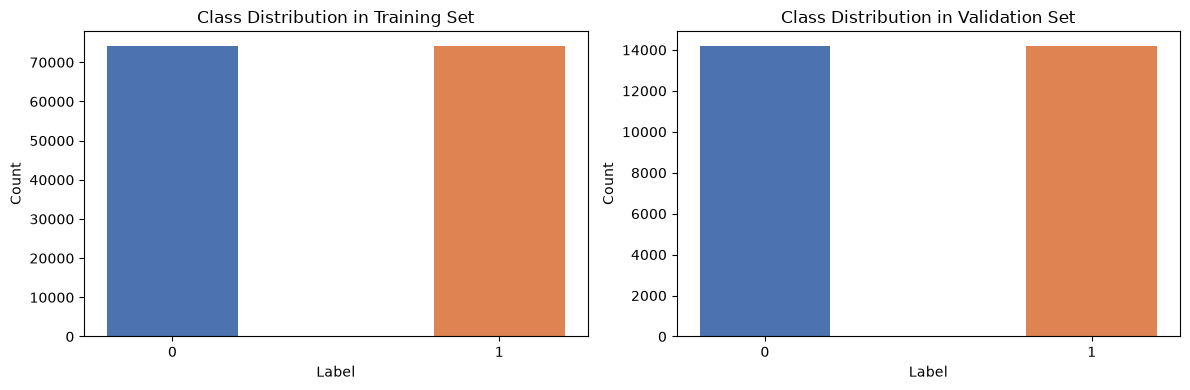

Class Distribution in Training Set:
Negative 0: 74192
Positive 1: 74196

Class Distribution in Validation Set:
Negative 0: 14197
Positive 1: 14199


In [ ]:
labels = ["0", "1"]
class_counts_train = train_df["Label"].value_counts().sort_index().tolist()
class_counts_val = val_df["Label"].value_counts().sort_index().tolist()

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.bar(labels, class_counts_train, width=0.4, color=["#4C72B0", "#DD8452"])
plt.title("Class Distribution in Training Set")
plt.xlabel("Label")
plt.ylabel("Count")

plt.subplot(1, 2, 2)
plt.bar(labels, class_counts_val, width=0.4, color=["#4C72B0", "#DD8452"])
plt.title("Class Distribution in Validation Set")
plt.xlabel("Label")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

print("Class Distribution in Training Set:")
print(f"Negative {labels[0]}: {class_counts_train[0]}")
print(f"Positive {labels[1]}: {class_counts_train[1]}")
print()
print("Class Distribution in Validation Set:")
print(f"Negative {labels[0]}: {class_counts_val[0]}")
print(f"Positive {labels[1]}: {class_counts_val[1]}")

In [ ]:
train_data = train_df.copy()

In [ ]:
train_data["Length"] = train_data["Text"].apply(lambda x: len(x))               #character count     
train_data["Word_count"] = train_data["Text"].apply(lambda x: len(x.split()))
train_data["Mean_word_length"] = train_data["Text"].apply(lambda x: np.mean([len(word) for word in x.split()]))
train_data["Mean_sentence_length"] = train_data["Text"].apply(lambda x: np.mean([len(sent) for sent in tokenize.sent_tokenize(x)]))

print(f"Length of a sample tweet: {train_data['Length'][0]}")
print(f"Word count in a sample tweet: {train_data['Word_count'][0]}")
print(f"Mean word length in a sample tweet: {train_data['Mean_word_length'][0]}")
print(f"Mean sentence length in a sample tweet: {train_data['Mean_sentence_length'][0]}")
train_data.head(10)

Length of a sample tweet: 45
Word count in a sample tweet: 7
Mean word length in a sample tweet: 5.428571428571429
Mean sentence length in a sample tweet: 45.0


,ID,Text,Label,Length,Word_count,Mean_word_length,Mean_sentence_length
0,189385,@whoisralphie dude I'm so bummed ur leaving!,0,45,7,5.428571,45.0
1,58036,"oh my god, a severed foot was foun in a wheely...",0,132,26,4.076923,43.0
2,190139,I end up &quot;dog dialing&quot; sumtimes. Wha...,1,162,25,5.480000,53.0
3,99313,@_rachelx meeeee toooooo!,0,26,3,7.666667,25.0
4,157825,"I was hoping I could stay home and work today,...",0,100,21,3.761905,99.0
5,130560,says plurk karma finally reached the 50s. stil...,0,98,13,6.538462,23.5
6,121871,"Good to hear it @Arth This is a bit more, but ...",1,142,26,4.461538,70.5
7,86813,@davorg in that case im gonna start tweeting a...,1,114,21,4.428571,113.0
8,197517,"@belunyc its alright love, how are you?",1,41,7,4.714286,39.0
9,6937,@brightondoll haha that has to be the best ana...,1,122,22,4.545455,29.5


In [ ]:
def plot_feature_stats(col):
    print()
    plt.figure(figsize=(12, 4))
    plt.subplot(1,2,1)
    sns.boxplot(data=train_data, x='Label', y=col, hue='Label', legend=False)
    plt.ylabel(col, labelpad=12.5)
    
    plt.subplot(1,2,2)
    sns.kdeplot(data=train_data, x=col, hue='Label')
    plt.legend(labels=['Positive (1)', 'Negative (0)'])
    plt.xlabel('')
    plt.ylabel('')
    
    plt.tight_layout()
    plt.show()
    

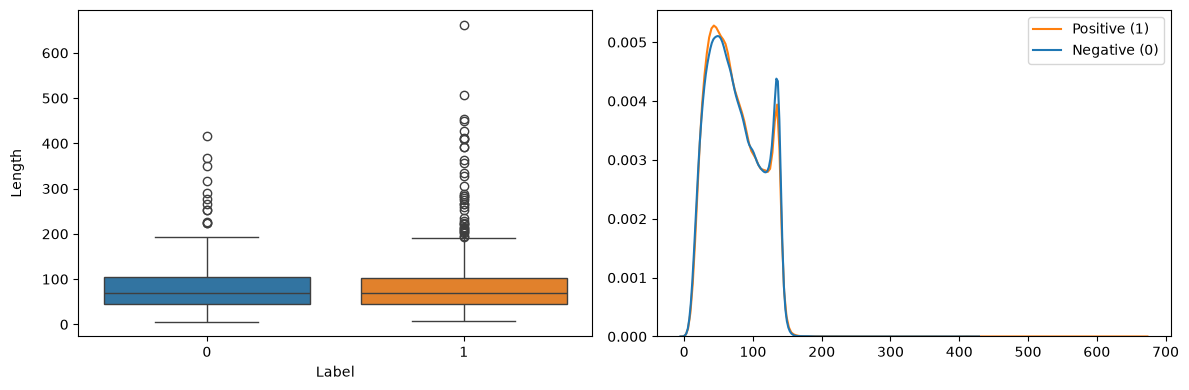

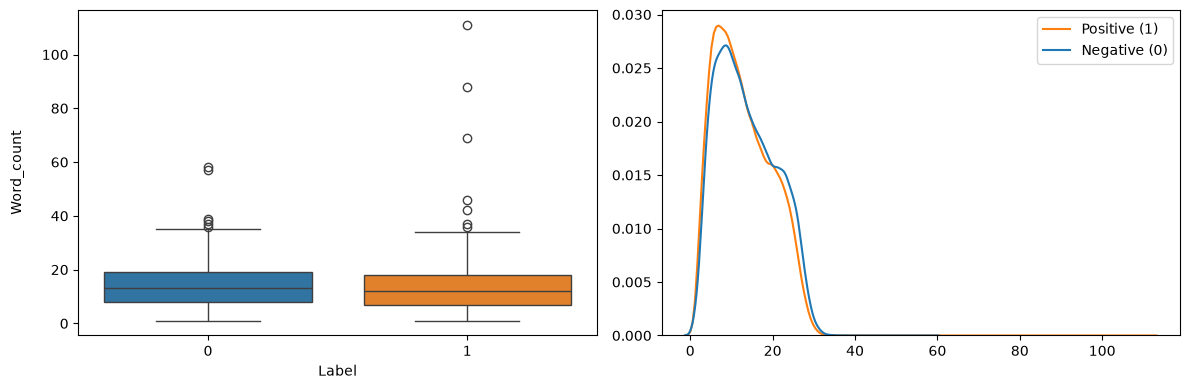

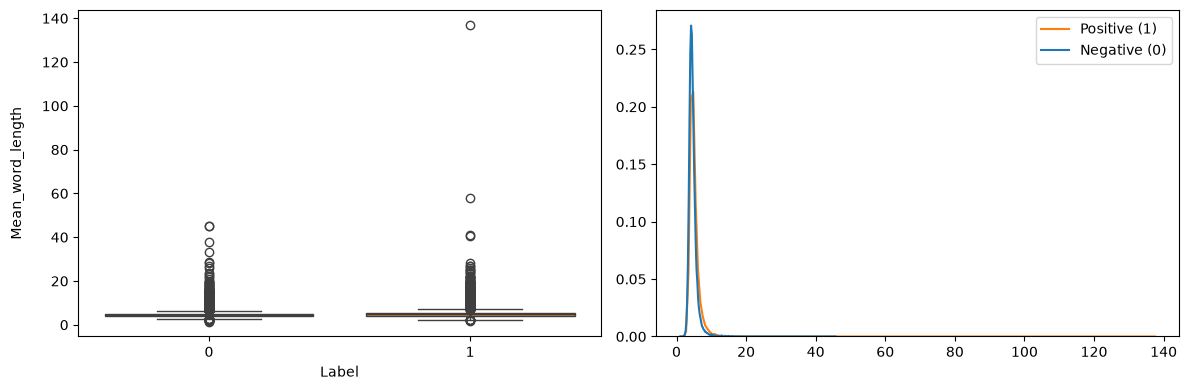

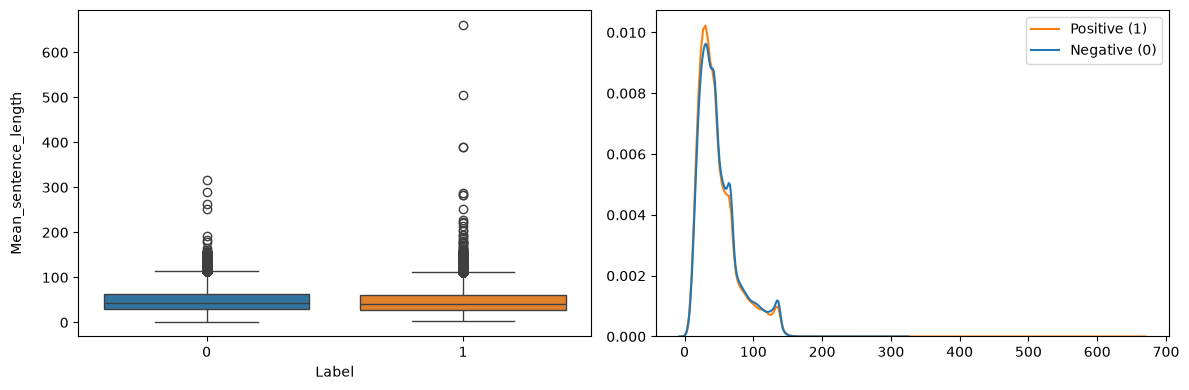

In [ ]:
features = train_data.columns.to_list()[3:]

for feature in features:
    plot_feature_stats(feature)

#### Text Preprocessing:

In [ ]:
def replace_emoticons(text):
    text = re.sub(r"</3", " heartbroken ", text)
    text = re.sub(r"<3",  " love ", text)
    text = re.sub(r":'\(", " crying ", text)
    text = re.sub(r":d",  " laugh ", text)
    text = re.sub(r":-d", " laugh ", text)
    text = re.sub(r"=d",  " laugh ", text)
    text = re.sub(r"xd",  " laugh ", text)
    text = re.sub(r"d:",  " laugh ", text)
    text = re.sub(r";\)",  " wink ", text)
    text = re.sub(r";-\)", " wink ", text)
    text = re.sub(r";d",   " wink ", text)
    text = re.sub(r":p",   " playful ", text)
    text = re.sub(r":-p",  " playful ", text)
    text = re.sub(r"=p",   " playful ", text)
    text = re.sub(r";p",   " playful ", text)
    text = re.sub(r"xp",   " playful ", text)
    text = re.sub(r":/",   " confused ", text)
    text = re.sub(r":-/",  " confused ", text)
    text = re.sub(r"=/",   " confused ", text)
    text = re.sub(r":\\",  " confused ", text)
    text = re.sub(r":o",   " surprised ", text)
    text = re.sub(r":-o",  " surprised ", text)
    text = re.sub(r":\(",  " sad ", text)
    text = re.sub(r":-\(", " sad ", text)
    text = re.sub(r"=\(",  " sad ", text)
    text = re.sub(r"\):",  " sad ", text)
    text = re.sub(r";\(",  " sad ", text)
    text = re.sub(r":\)",  " smile ", text)
    text = re.sub(r":-\)", " smile ", text)
    text = re.sub(r"=\)",  " smile ", text)
    text = re.sub(r"\(:",  " smile ", text)
    text = re.sub(r":\*",  " kiss ", text)
    text = re.sub(r":-\*", " kiss ", text)
    return text

abbreviations = {
    
    "lol": "laugh", "lmao": "laugh", "lmfao": "laugh", "rofl": "laugh",
    "omg": "oh my god",
    "btw": "by the way",
    "idk": "i do not know",
    "ily": "i love you",
    "tbh": "to be honest",
    "imo": "in my opinion",
    "imho": "in my humble opinion",
    "asap": "as soon as possible",
    "fyi": "for your information",
    "jk": "just kidding",
    "ttyl": "talk to you later",
    "atm": "at the moment",
    "brb": "be right back",
    "dm": "direct message",

    "thx": "thanks", "thnx": "thanks",
    "ty": "thank you",
    "pls": "please", "plz": "please",

    "tmrw": "tomorrow", "tmr": "tomorrow",
    "2moro": "tomorrow", "2morrow": "tomorrow",
    "2day": "today",
    "2nite": "tonight", "2night": "tonight", "tonite": "tonight",

    "1st": "first", "2nd": "second", "3rd": "third",
    "b4": "before",
}

slang = {

    "luv": "love",
    "cuz": "because", "coz": "because", "bcuz": "because",
    "wit": "with",
    "wat": "what",
    "kno": "know",
    "hav": "have",
    "ya": "you",
    "lil": "little",
    "u": "you",
    "ur": "your",
    "r": "are",

    "yea": "yes", "yup": "yes",
    "nope": "no", "nah": "no",

    "bro": "brother",
    "sis": "sister",
    "fam": "family",
    "bday": "birthday",
    "pic": "picture", "pics": "pictures",
    "fav": "favorite",
    "vid": "video",
    "prob": "probably", "probs": "probably",

    "goin": "going", "doin": "doing", "havin": "having",
    "lovin": "loving", "hatin": "hating", "tryin": "trying",
    "seein": "seeing", "sayin": "saying", "eatin": "eating",
    "playin": "playing", "livin": "living", "workin": "working",
    "runnin": "running", "movin": "moving", "missin": "missing",
    "killin": "killing", "freakin": "freaking", "comin": "coming",
}

contractions = {
   
    "i'm": "i am", "it's": "it is", "he's": "he is", "she's": "she is",
    "we're": "we are", "you're": "you are", "they're": "they are",
    "that's": "that is", "what's": "what is", "where's": "where is",
    "there's": "there is", "here's": "here is", "who's": "who is",
    "how's": "how is",

    "i've": "i have", "you've": "you have", "we've": "we have",
    "they've": "they have",

    "i'll": "i will", "you'll": "you will", "he'll": "he will",
    "she'll": "she will", "we'll": "we will", "they'll": "they will",
    "it'll": "it will",

    "i'd": "i would", "you'd": "you would", "he'd": "he would",
    "she'd": "she would", "we'd": "we would", "they'd": "they would",

    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "can't": "can not", "won't": "will not", "wouldn't": "would not",
    "shouldn't": "should not", "couldn't": "could not", "mustn't": "must not",
    "isn't": "is not", "aren't": "are not", "wasn't": "was not",
    "weren't": "were not", "hasn't": "has not", "haven't": "have not",
    "hadn't": "had not",

    "let's": "let us",

    "im": "i am", "hes": "he is", "shes": "she is",
    "youre": "you are", "theyre": "they are",
    "thats": "that is", "whats": "what is", "wheres": "where is",
    "theres": "there is", "heres": "here is",

    "ive": "i have", "youve": "you have",

    "dont": "do not", "doesnt": "does not", "didnt": "did not",
    "cant": "can not", "wont": "will not", "wouldnt": "would not",
    "shouldnt": "should not", "couldnt": "could not",
    "isnt": "is not", "wasnt": "was not",
    "havent": "have not", "hasnt": "has not",
    "wanna": "want to", "gonna": "going to",
    "gotta": "got to", "dunno": "do not know",
    "kinda": "kind of", "sorta": "sort of",
    "outta": "out of", "lemme": "let me",
    "gimme": "give me", "yall": "you all",
}


In [ ]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

def apply_lemmatization(text):
    return " ".join(token.lemma_ for token in nlp(text))

In [ ]:
def remove_mentions(text):
    return re.sub(r"@\w+", "", text)

def remove_urls(text):
    return re.sub(r"http\S+|www\S+|https\S+", " ", text)

def remove_digits(text):
    return re.sub(r"\d+", "", text)

def remove_alphanumeric(text):
    return re.sub(r"\w*\d\w*", "", text)

def remove_short_words(text):
    return " ".join(w for w in text.split() if len(w) > 1)

def remove_punctuation(text):
    return re.sub(r"[^\w\s]", " ", text)

def remove_extra_spaces(text):
    return re.sub(r"\s+", " ", text).strip()

def convert_to_lowercase(text):
    return text.lower()

def remove_repeated_chars(text):
    return re.sub(r"(.)\1{2,}", r"\1", text)

# def remove_stopwords(text):
#     stop_words = set(stopwords.words('english'))
#     return " ".join([word for word in text.split() if word not in stop_words])

def fix_mojibake(text):
    return ftfy.fix_text(text)

def replace_abbreviations(text):
    return " ".join([abbreviations.get(word, word) for word in text.split()])

def replace_slang(text):
    return " ".join([slang.get(word, word) for word in text.split()])

def replace_contractions(text):
    return " ".join([contractions.get(word, word) for word in text.split()])


def clean_text(text):

    text = fix_mojibake(text)               # encodes characters correctly
    text = convert_to_lowercase(text)
    text = html.unescape(text)          #recovers html entities
    text = remove_mentions(text)
    text = remove_urls(text)
    text = replace_emoticons(text)

    text = replace_abbreviations(text)
    text = replace_slang(text)
    text = replace_contractions(text)

    text = remove_digits(text)
    text = remove_punctuation(text)
    
    text = remove_alphanumeric(text)
    text = remove_short_words(text)
    text = remove_repeated_chars(text)
    text = apply_lemmatization(text)         
    text = remove_extra_spaces(text)

    return text

In [ ]:
train_df["Text"].head(20)

0         @whoisralphie dude  I'm so bummed ur leaving!
1     oh my god, a severed foot was foun in a wheely...
2     I end up &quot;dog dialing&quot; sumtimes. Wha...
3                            @_rachelx meeeee toooooo! 
4     I was hoping I could stay home and work today,...
5     says plurk karma finally reached the 50s. stil...
6     Good to hear it @Arth This is a bit more, but ...
7     @davorg in that case im gonna start tweeting a...
8             @belunyc its alright love, how are you?  
9     @brightondoll haha that has to be the best ana...
10    @AlpacaFarmgirl Biscuit is our cat. We've had ...
11    @1capplegate I'm so sad about Sam Who  it was ...
12    trying to stay healthy. 2 of 4 of this Devine ...
13    My bro stole my big bag, my pink bag is gone. ...
14                 my hair wont go right! sighsighsigh 
15       I got bored so I slept, now I'm a little sad. 
16    @LunaBellaMUA   I'm probably being blonde...bu...
17    @janinaz love this game on PS3 too ^^ i th

In [ ]:
train_df["Text"] = train_df["Text"].apply(clean_text)
val_df["Text"]   = val_df["Text"].apply(clean_text)
test_df["Text"]  = test_df["Text"].apply(clean_text)

Stopwords were retained during preprocessing, as removing them was found to decrease the model’s baseline performance.

In [ ]:
train_df["Text"].head(20)

0                        dude be so bummed your leaving
1     oh my god sever foot be foun in wheely bin in ...
2     end up dog dial sumtime what be dog dialing yo...
3                                                  I to
4     be hop could stay home and work today but look...
5     say plurk karma finally reach the still no hea...
6     good to hear it this be bit more but la four t...
7     in that case be go to start tweet about nympho...
8                           its alright love how be you
9     haha that have to be the good analogy ever mog...
10    biscuit be our cat we have have he for year an...
11    be so sad about sam who it be my favorite sitc...
12    try to stay healthy of of this devine family f...
13    my brother steal my big bag my pink bag be go ...
14               my hair will not go right sighsighsigh
15                  get bore so sleep now be little sad
16        be probably be blonde but my reaction to what
17    love this game on ps too think it be my fa

Term Frequency Analysis:

In [ ]:
corpus = [tokens for tokens_list in train_df['Text'].apply(lambda x: x.split()) for tokens in tokens_list]

most_common_words = Counter(corpus).most_common(10)
most_common_words

[('be', 95206),
 ('to', 57418),
 ('the', 49305),
 ('you', 33488),
 ('not', 32005),
 ('my', 30305),
 ('it', 28624),
 ('and', 28607),
 ('have', 26652),
 ('do', 22747)]

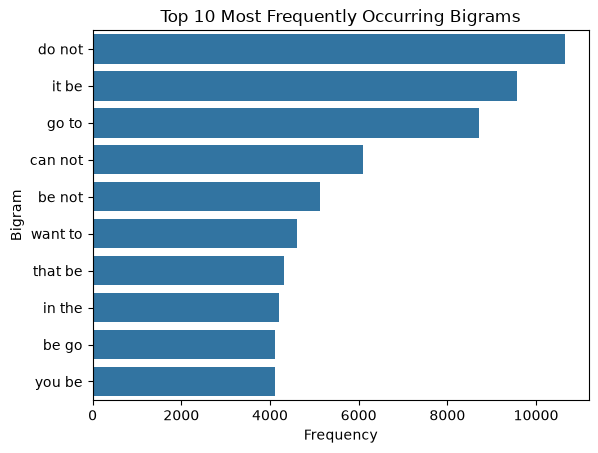

In [ ]:
vectorizer = CountVectorizer(ngram_range=(2, 2))
x = vectorizer.fit_transform(train_df["Text"])

bigram_freqs = pd.Series(x.sum(axis=0).A1, index=vectorizer.get_feature_names_out())
most_frequent_bigrams = bigram_freqs.nlargest(10)

sns.barplot(x=most_frequent_bigrams.values, y=most_frequent_bigrams.index)
plt.title("Top 10 Most Frequently Occurring Bigrams")
plt.xlabel("Frequency")
plt.ylabel("Bigram")
plt.show()

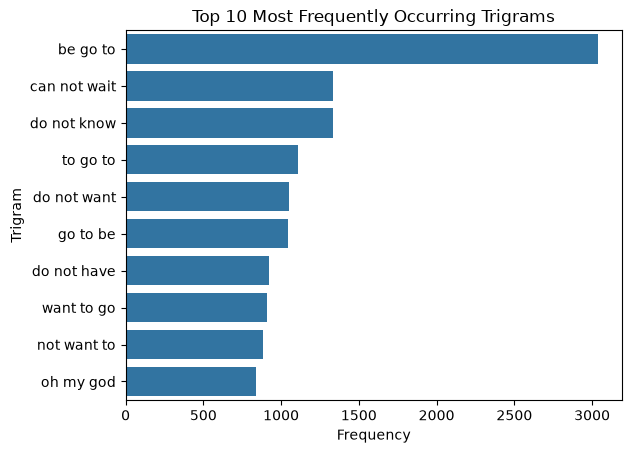

In [ ]:
vectorizer = CountVectorizer(ngram_range=(3, 3))
x = vectorizer.fit_transform(train_df["Text"])

trigram_freqs = pd.Series(x.sum(axis=0).A1, index=vectorizer.get_feature_names_out())
most_frequent_trigrams = trigram_freqs.nlargest(10)

sns.barplot(x=most_frequent_trigrams.values, y=most_frequent_trigrams.index)
plt.title("Top 10 Most Frequently Occurring Trigrams")
plt.xlabel("Frequency")
plt.ylabel("Trigram")
plt.show()

#### Model Development and Evaluation:

We are using the tf-idf method for feature extraction. We are initially training the model with the default parameters for both ```TfidfVectorizer()``` and ```LogisticRegression()```.

In [ ]:
tfidf = TfidfVectorizer()
x_train = tfidf.fit_transform(train_df["Text"])
y_train = train_df["Label"]

model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

train_preds = model.predict(x_train)

Evaluating the model on the validation set:

In [ ]:
x_val = tfidf.transform(val_df["Text"])
y_val = val_df["Label"]

preds_val = model.predict(x_val)            #model predictions on validation set

Metric scores on training and validation set:

In [ ]:
print(f"Accuracy on Training Set:  {accuracy_score(y_train, train_preds):.4f}")
print(f"Precision on Training Set: {precision_score(y_train, train_preds):.4f}")
print(f"Recall on Training Set:    {recall_score(y_train, train_preds):.4f}")
print(f"F1-score on Training Set:  {f1_score(y_train, train_preds):.4f}")
print()
print(f"Accuracy on Validation Set:  {accuracy_score(y_val, preds_val):.4f}")
print(f"Precision on Validation Set: {precision_score(y_val, preds_val):.4f}")
print(f"Recall on Validation Set:    {recall_score(y_val, preds_val):.4f}")
print(f"F1-score on Validation Set:  {f1_score(y_val, preds_val):.4f}")

Accuracy on Training Set:  0.8141
Precision on Training Set: 0.8078
Recall on Training Set:    0.8244
F1-score on Training Set:  0.8160

Accuracy on Validation Set:  0.7881
Precision on Validation Set: 0.7830
Recall on Validation Set:    0.7971
F1-score on Validation Set:  0.7900


Training and evaluating the model using cross-validation:

In [ ]:
x_train = pd.concat([train_df["Text"], val_df["Text"]],ignore_index=True)   #combinig training and validation into one dataset
y_train = pd.concat([train_df["Label"], val_df["Label"]],ignore_index=True)

pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('LogisticRegression', LogisticRegression(max_iter=1000))
])

scores = cross_validate(pipeline, x_train, y_train, cv=5, scoring=['accuracy', 'precision', 'recall', 'f1'], return_train_score=True)

In [ ]:
print(f"Accuracy on Training Set (cross-validation):  {scores['train_accuracy'].mean():.4f}")
print(f"Precision on Training Set (cross-validation): {scores['train_precision'].mean():.4f}")
print(f"Recall on Training Set (cross-validation):    {scores['train_recall'].mean():.4f}")
print(f"F1-score on Training Set (cross-validation):  {scores['train_f1'].mean():.4f}")
print()
print(f"Accuracy on Validation Set (cross-validation):  {scores['test_accuracy'].mean():.4f}")
print(f"Precision on Validation Set (cross-validation): {scores['test_precision'].mean():.4f}")
print(f"Recall on Validation Set (cross- validation):    {scores['test_recall'].mean():.4f}")
print(f"F1-score on Validation Set (cross-validation):  {scores['test_f1'].mean():.4f}")

Accuracy on Training Set (cross-validation):  0.8155
Precision on Training Set (cross-validation): 0.8093
Recall on Training Set (cross-validation):    0.8255
F1-score on Training Set (cross-validation):  0.8173

Accuracy on Validation Set (cross-validation):  0.7833
Precision on Validation Set (cross-validation): 0.7785
Recall on Validation Set (cross- validation):    0.7920
F1-score on Validation Set (cross-validation):  0.7852


The scores on the validation set are close to those on the training set. This is a first indication that our model has neither high bias (underfitting) nor high variance (overfitting). 

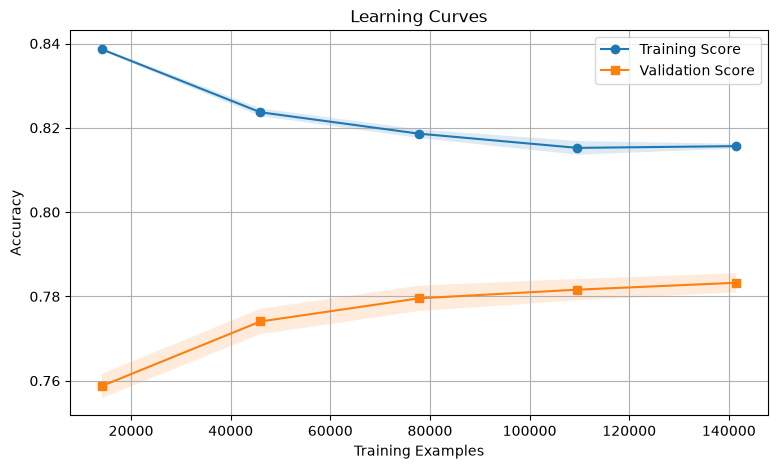

In [ ]:
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('LogisticRegression', LogisticRegression(max_iter=1000))
])

train_sizes, train_scores, val_scores = learning_curve(pipeline, x_train, y_train, cv=5)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean,   val_std   = val_scores.mean(axis=1),   val_scores.std(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training Score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
plt.plot(train_sizes, val_mean, marker="s", label="Validation Score")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
plt.xlabel("Training Examples")
plt.ylabel("Accuracy")
plt.title("Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

#### Hyperparameter tuning using optuna:

We are trying to maximize the accuracy on the validation set. We are going to use cross-validation as it provides a more reliable evaluation than a single train-val split and helps ensure our model generalizes well on unseen data.

In our first study, we explore a broad range of parameter values to identify promising regions of the search space.

In [ ]:
def objective(trial):

    max_features = trial.suggest_int("max_features", 50000, 70000, step=1000)
    ngram_upper = trial.suggest_int("ngram_upper", 1, 3)
    ngram_range = (1, ngram_upper)
    C = trial.suggest_float("C", 0.01, 7.0, log=True)          
    max_df = trial.suggest_float("max_df", 0.9, 1.0, step=0.01)    
    min_df = trial.suggest_float("min_df", 0.0001, 0.0005, step=0.0001)  
    solver = trial.suggest_categorical("solver", ["liblinear", "lbfgs"])

    if solver == "liblinear":
        l1_ratio = trial.suggest_categorical("l1_ratio", [0.0, 1.0])
    elif solver == "lbfgs":
        l1_ratio = 0.0

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=max_features, min_df=min_df, max_df=max_df, ngram_range=ngram_range)),
        ("clf", LogisticRegression(max_iter=1500, random_state=RANDOM_SEED, C=C, solver=solver, l1_ratio=l1_ratio)),
    ])

    return cross_val_score(pipeline, x_train, y_train, cv=5).mean()


study_broad = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_SEED))
study_broad.optimize(objective, n_trials=90)

print(f"Best Accuracy Score: {study_broad.best_value:.6f}")
print(f"Best params: {study_broad.best_params}")

[I 2026-10-31 16:12:48,703] A new study created in memory with name: no-name-5c700052-538a-4553-84c7-553e1e687426
[I 2026-10-31 16:13:18,211] Trial 0 finished with value: 0.8003665653663328 and parameters: {'max_features': 57000, 'ngram_upper': 3, 'C': 1.2094684088961507, 'max_df': 0.96, 'min_df': 0.0001, 'solver': 'liblinear', 'l1_ratio': 0.0}. Best is trial 0 with value: 0.8003665653663328.
[I 2026-10-31 16:13:23,633] Trial 1 finished with value: 0.7792334374149246 and parameters: {'max_features': 64000, 'ngram_upper': 1, 'C': 5.747627570741735, 'max_df': 0.99, 'min_df': 0.0002, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.8003665653663328.
[I 2026-10-31 16:13:37,818] Trial 2 finished with value: 0.785478346169285 and parameters: {'max_features': 56000, 'ngram_upper': 2, 'C': 0.16940488357126882, 'max_df': 0.93, 'min_df': 0.0004, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.8003665653663328.
[I 2026-10-31 16:13:52,123] Trial 3 finished with value: 0.7926056908908986 and par

Best Accuracy Score: 0.800423
Best params: {'max_features': 62000, 'ngram_upper': 3, 'C': 1.1746671942682758, 'max_df': 0.97, 'min_df': 0.0001, 'solver': 'liblinear', 'l1_ratio': 0.0}


In our second study, we focus on a narrower range of parameter values chosen around the region where the broad search converged.

In [ ]:
def objective(trial):

    max_features = trial.suggest_int("max_features", 55000, 66000, step=1000)
    ngram_upper = trial.suggest_int("ngram_upper", 2, 3)
    ngram_range = (1, ngram_upper)
    C = trial.suggest_float("C", 0.5, 4.0, log=True)          
    max_df = trial.suggest_float("max_df", 0.95, 1.0, step=0.01)    
    min_df = trial.suggest_float("min_df", 0.0001, 0.0005, step=0.0001)  
    solver = trial.suggest_categorical("solver", ["liblinear", "lbfgs"])

    if solver == "liblinear":
        l1_ratio = trial.suggest_categorical("l1_ratio", [0.0, 1.0])
    elif solver == "lbfgs":
        l1_ratio = 0.0

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(max_features=max_features, min_df=min_df, max_df=max_df, ngram_range=ngram_range)),
        ("clf", LogisticRegression(max_iter=1500, random_state=RANDOM_SEED, C=C, solver=solver, l1_ratio=l1_ratio)),
    ])

    return cross_val_score(pipeline, x_train, y_train, cv=5).mean()


study_narrow = optuna.create_study(direction="maximize", sampler=TPESampler(seed=RANDOM_SEED))
study_narrow.optimize(objective, n_trials=90)

print(f"Best Accuracy Score: {study_narrow.best_value:.6f}")
print(f"Best params: {study_narrow.best_params}")

[I 2026-10-31 16:46:13,315] A new study created in memory with name: no-name-a3e72d33-c8a4-4c74-b0fd-7b9ebed1b40f
[I 2026-10-31 16:46:36,543] Trial 0 finished with value: 0.7983245229946067 and parameters: {'max_features': 59000, 'ngram_upper': 3, 'C': 2.2910069344764312, 'max_df': 0.98, 'min_df': 0.0001, 'solver': 'liblinear', 'l1_ratio': 0.0}. Best is trial 0 with value: 0.7983245229946067.
[I 2026-10-31 16:46:47,576] Trial 1 finished with value: 0.7938048922950254 and parameters: {'max_features': 63000, 'ngram_upper': 2, 'C': 3.757386581819488, 'max_df': 0.99, 'min_df': 0.0002, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.7983245229946067.
[I 2026-10-31 16:47:08,901] Trial 2 finished with value: 0.7906880902666351 and parameters: {'max_features': 58000, 'ngram_upper': 3, 'C': 1.2275953242802318, 'max_df': 0.96, 'min_df': 0.0004, 'solver': 'lbfgs'}. Best is trial 0 with value: 0.7983245229946067.
[I 2026-10-31 16:47:22,788] Trial 3 finished with value: 0.7920343695316291 and par

Best Accuracy Score: 0.800451
Best params: {'max_features': 57000, 'ngram_upper': 3, 'C': 1.1963820375735141, 'max_df': 0.99, 'min_df': 0.0001, 'solver': 'liblinear', 'l1_ratio': 0.0}


In [ ]:
if study_narrow.best_value >= study_broad.best_value:
    best_value = study_narrow.best_value
    best_params = study_narrow.best_params
else:
    best_value = study_broad.best_value
    best_params = study_broad.best_params

print(f"Overall best accuracy: {best_value:.6f}")
print(f"Overall best params: {best_params}")

Overall best accuracy: 0.800451
Overall best params: {'max_features': 57000, 'ngram_upper': 3, 'C': 1.1963820375735141, 'max_df': 0.99, 'min_df': 0.0001, 'solver': 'liblinear', 'l1_ratio': 0.0}


#### Retraining the model using the best hyperparameter values returned by optuna:

In [ ]:
pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=best_params["max_features"],
        ngram_range=(1, best_params["ngram_upper"]),
        min_df=best_params["min_df"],
        max_df=best_params["max_df"],
    )),
    ("clf", LogisticRegression(
        C=best_params["C"],
        solver=best_params["solver"],
        l1_ratio=best_params.get("l1_ratio", 0.0),
        max_iter=1500,
        random_state=RANDOM_SEED,
    ))
])

In [ ]:
pipeline.fit(x_train, y_train)
x_test = test_df["Text"]
y_test = test_df["Label"]

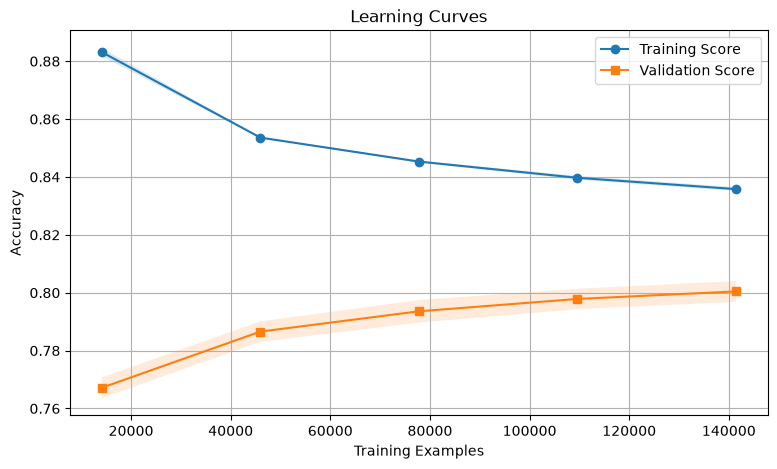

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(pipeline, x_train, y_train, cv=5)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean,   val_std   = val_scores.mean(axis=1),   val_scores.std(axis=1)

plt.figure(figsize=(9, 5))
plt.plot(train_sizes, train_mean, marker="o", label="Training Score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15)
plt.plot(train_sizes, val_mean, marker="s", label="Validation Score")
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
plt.xlabel("Training Examples")
plt.ylabel("Accuracy")
plt.title("Learning Curves")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
predictions = pipeline.predict(x_test)

In [ ]:
print(f"Accuracy on Test Set:  {accuracy_score(y_test, predictions):.4f}")
print(f"Precision on Test Set: {precision_score(y_test, predictions):.4f}")
print(f"Recall on Test Set:    {recall_score(y_test, predictions):.4f}")
print(f"F1-score on Test Set:  {f1_score(y_test, predictions):.4f}")

Accuracy on Test Set:  0.7993
Precision on Test Set: 0.7949
Recall on Test Set:    0.8067
F1-score on Test Set:  0.8008
